# Test manual PSF code

## Check can recreate the $\rho(f)$

In [28]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

import numpy as np
import psf as psf

import sys, os

import matplotlib
import matplotlib.pyplot as plt
import matplotlib as mpl

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
# Define basic parameters
psf_dir = '/zfs/nrodd/NPTFit/PSF_Testing/psf_dir/'
nside=128
num_f_bins = 10

In [3]:
# Calculate the PSF - weird value is to compare with what we have from Ben's tutorial
f_ary_1, df_rho_div_f_ary_1 = psf.make_PSF(psf_dir, nside, 0.1)
#f_ary_2, df_rho_div_f_ary_2 = psf.make_PSF(psf_dir, nside, 0.2)
#f_ary_3, df_rho_div_f_ary_3 = psf.make_PSF(psf_dir, nside, 0.3)
#f_ary_4, df_rho_div_f_ary_4 = psf.make_PSF(psf_dir, nside, 0.4)

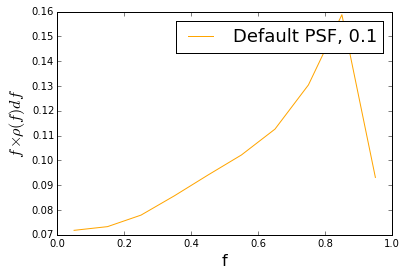

In [12]:
plt.plot(f_ary_1,f_ary_1**2*df_rho_div_f_ary_1,color='orange',label='Default PSF, 0.1')
#plt.plot(f_ary_2,f_ary_2**2*df_rho_div_f_ary_2,color='green',label='Default PSF, 0.2')
#plt.plot(f_ary_3,f_ary_3**2*df_rho_div_f_ary_3,color='blue',label='Default PSF, 0.3')
#plt.plot(f_ary_4,f_ary_4**2*df_rho_div_f_ary_4,color='Red',label='Default PSF, 0.4')
plt.xlabel('f',fontsize=16)
plt.ylabel('$f \\times \\rho(f) df $',fontsize=16)
plt.legend(fontsize=18)
plt.show()

In [ ]:
# Check normalisation
print np.sum(f_ary_1**2*df_rho_div_f_ary_1)
print np.sum(f_ary_2**2*df_rho_div_f_ary_2)
print np.sum(f_ary_3**2*df_rho_div_f_ary_3)
print np.sum(f_ary_4**2*df_rho_div_f_ary_4)

In [8]:
# More general function
import psf_general as psfg

In [9]:
psfgi = psfg.psf_general(0.1)
f_ary_1_test, df_rho_div_f_ary_1_test = psfgi.make_PSF()

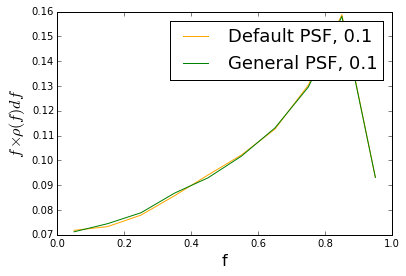

In [13]:
plt.plot(f_ary_1,f_ary_1**2*df_rho_div_f_ary_1,color='orange',label='Default PSF, 0.1')
plt.plot(f_ary_1_test,f_ary_1_test**2*df_rho_div_f_ary_1_test,color='green',label='General PSF, 0.1')
plt.xlabel('f',fontsize=16)
plt.ylabel('$f \\times \\rho(f) df $',fontsize=16)
plt.legend(fontsize=18)
plt.show()

## Confirm the two distributions separately as a more detailed check

In [39]:
# Check difference in dp calculation

import gauss_pdf as gp
sigma_PSF_deg=0.1
n_pts_per_psf=100000
gpi = gp.gauss_pdf(sigma_PSF_deg)

xyz = np.random.normal(size=(1, 3))
xyz_unit = np.divide(xyz, np.linalg.norm(xyz, axis=1)[:, None])
theta_c = np.arccos(xyz_unit[:,2])
phi_c = np.arctan2(xyz_unit[:,1], xyz_unit[:,0])

theta_c=[np.pi/2]
phi_c=[0.0]

#dp = np.random.normal(scale=np.sqrt(2)*sigma_PSF_deg*np.pi/180., size=n_pts_per_psf)
#dangle = np.random.uniform(0,2*np.pi,n_pts_per_psf)
#dtheta3 = dp*np.sin(dangle)
#dphi3 = dp*np.cos(dangle)/(np.sin(theta_c[0]+dtheta1/2))

dtheta1 = np.random.normal(scale=sigma_PSF_deg*np.pi/180., size=n_pts_per_psf)
dphi1 = np.random.normal(scale=sigma_PSF_deg*np.pi/180., size=n_pts_per_psf)/(np.sin(theta_c[0]+dtheta1/2))

dp = gpi.gauss_pdf_draw(n_pts_per_psf)
dangle = np.random.uniform(0,2*np.pi,n_pts_per_psf)
dtheta2 = dp*np.sin(dangle)
dphi2 = dp*np.cos(dangle)/(np.sin(theta_c[0]+dtheta2/2))

transform: <function <lambda> at 0x7f9842cf07d0>
Index: [[58 79 46 ..., 46 70 68]]
Index: [[58 79 46 ..., 46 70 68]]


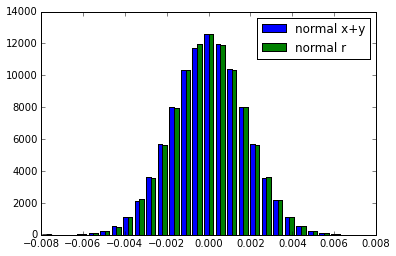

In [48]:
bins = np.linspace(-0.008,0.008, 30)
plt.hist([dtheta1,dtheta2],bins,label=['normal x+y','normal r'])
plt.legend()
plt.show()

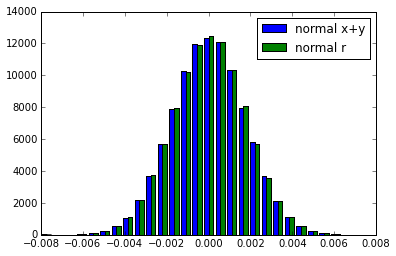

In [49]:
bins = np.linspace(-0.008,0.008, 30)
plt.hist([dphi1,dphi2],bins,label=['normal x+y','normal r'])
plt.legend()
plt.show()

## Compare the time of the default cython and python code

In [14]:
%timeit f_ary_1, df_rho_div_f_ary_1 = psf.make_PSF(psf_dir, nside, 0.1)
%timeit f_ary_1_test, df_rho_div_f_ary_1_test = psfgi.make_PSF()

1 loop, best of 3: 24.9 s per loop
1 loop, best of 3: 1min 1s per loop


# Test the CDF code

In [58]:
# Define basics
sigma_PSF_deg = 0.5
sampling = 10000
def gauss_fn(r=0.1):
    return 2*np.pi*r*np.exp(-r**2/(2.0*(sigma_PSF_deg*np.pi/180.)**2))

rarr = np.linspace(0,5*sigma_PSF_deg,sampling)
pdf = gauss_fn(rarr)

# Define the distribution function
# We don't want interpolation
shape = pdf.shape
pdf = pdf.ravel() # don't need this if we've set this up correctly
transform = lambda i:[rarr[idr] for idr in np.array(i)]
sortindex = np.argsort(pdf, axis=None)
pdf = pdf[sortindex]
cdf = np.cumsum(pdf)
choice = np.random.uniform(high = cdf[-1], size = 5)
index = np.searchsorted(cdf, choice)
index = [sortindex[index]]
output = transform(index)
print output[0]

[ 0.01025103  0.00525053  0.01725173  0.01150115  0.00850085]


In [66]:
print [rarr[idr] for idr in np.array([2,3,4])]

[0.00050005000500050005, 0.00075007500750075002, 0.0010001000100010001]


In [67]:
print rarr[2]

0.000500050005001


In [73]:
# Define basics
sigma_PSF_deg = 0.5
sampling = 10000
def gauss_fn(r=0.1):
    return 2*np.pi*r*np.exp(-r**2/(2.0*(sigma_PSF_deg*np.pi/180.)**2))

rarr = np.linspace(0,5*sigma_PSF_deg,sampling)
pdf = gauss_fn(rarr)

# Define the distribution function
# We don't want interpolation
shape = pdf.shape
pdf = pdf.ravel() # don't need this if we've set this up correctly
transform = lambda i:[rarr[idr] for idr in np.array(i)]
sortindex = np.argsort(pdf, axis=None)
pdf = pdf[sortindex]
cdf = np.cumsum(pdf)
choice = np.random.uniform(high = cdf[-1], size = 5)
index = np.searchsorted(cdf, choice)
index = [sortindex[index]]
output = transform(index)
print index[0]
output2 = rarr[index[0]]
print output[0]
print output2

[41 28 31 79 43]
[ 0.01025103  0.0070007   0.00775078  0.01975198  0.01075108]
[ 0.01025103  0.0070007   0.00775078  0.01975198  0.01075108]


In [25]:
# Define basics
sigma_PSF_deg = 0.5
sampling = 10000
def gauss_fn(r=0.1):
    return 2*np.pi*r*np.exp(-r**2/(2.0*(sigma_PSF_deg*np.pi/180.)**2))

rarr = np.linspace(0,5*sigma_PSF_deg,sampling)
pdf = gauss_fn(rarr)

# Define the distribution function
# Simplified version
print pdf
sortindex = np.argsort(pdf, axis=None)
print sortindex
pdf = pdf[sortindex]
cdf = np.cumsum(pdf)
choice = np.random.uniform(high = cdf[-1], size = 5)
index = np.searchsorted(cdf, choice)
print index
index = sortindex[index]
print index
output = rarr[index]
print output

[ 0.          0.00157031  0.00313675 ...,  0.          0.          0.        ]
[   0 6663 6664 ...,   36   34   35]
[9973 9955 9984 9921 9954]
[49 60 43 83 15]
[ 0.01225123  0.0150015   0.01075108  0.02075208  0.00375038]


In [26]:
import pdf_sampler as pdfs
gauss = pdfs.pdf_sampler(rarr,gauss_fn(rarr))
print gauss(5)

[ 0.          0.00157031  0.00313675 ...,  0.          0.          0.        ]
[   0 6663 6664 ...,   36   34   35]
[9998 9926 9980 9945 9925]
[34  6 45 66 80]
[ 0.00850085  0.00150015  0.01125113  0.01650165  0.020002  ]


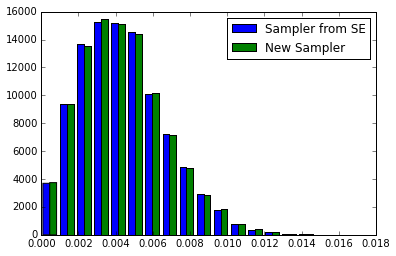

In [49]:
import gauss_pdf_newsamp as gpn
import gauss_pdf as gp

gpni = gpn.gauss_pdf(0.2)
gpi = gp.gauss_pdf(0.2)

gpnic = gpni.gauss_pdf_draw(100000)
gpic = gpi.gauss_pdf_draw(100000)

bins = np.linspace(0,0.2*np.pi/180*5, 20)
plt.hist([gpnic,gpic],bins,label=['Sampler from SE','New Sampler'])
plt.legend()
plt.show()

In [8]:
import numpy as np
psf_sigma_deg=0.5
psf_r_func = lambda r: np.exp(-r**2/(2.0*psf_sigma_deg*np.pi/180.)**2)

In [21]:
psf_r_func(5*psf_sigma_deg*np.pi/180)/psf_r_func(0*psf_sigma_deg*np.pi/180)*100

0.19304541362277092